# Digital Image Processing Lab – Task 03
## Image Enhancement and Intensity Transformations

**University:** The University of Azad Jammu and Kashmir  
**Department:** Software Engineering  
**Student Name:** Zoya Mazhar
**Roll Number:** 2024-SE-26
**Lab Task:** 03  
**Session:** 2024–28

### Objective
To implement and compare grayscale intensity transformations, histogram enhancement, and thresholding while preventing overflow.

### Required libraries
We will use NumPy for calculations, OpenCV for image processing, and Matplotlib for displaying images and graphs.

## Step 0 – Install and import the required libraries

Run the installation cell only if a library is missing. In Anaconda Jupyter Notebook, these commands install the libraries in the notebook's active Python environment.

In [1]:
%pip install numpy opencv-python matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 1 – Load and validate a grayscale image

Choose one JPG or PNG image that is at least **300 × 300 pixels**. Put the image in the same folder as this notebook.

Change `image.jpg` below to the exact name of your image. For example, if your file is named `flower.png`, write `flower.png`.

The original image is kept unchanged. We will create separate result images for every operation.

Image loaded successfully.
Image shape: (548, 559)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 244
The image is a valid 8-bit grayscale image.


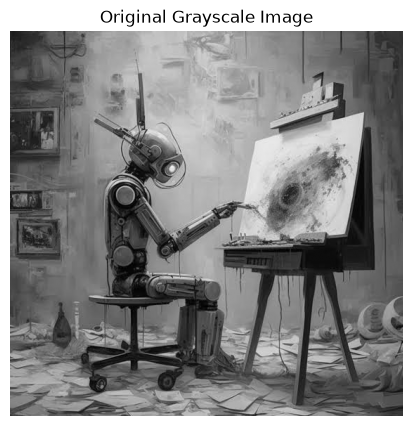

In [3]:
# Load the image directly in grayscale
image = cv2.imread("image.jpg", cv2.IMREAD_GRAYSCALE)

# Check whether the image was loaded
if image is None:
    print("Image not found. Check the image name and folder.")
else:
    print("Image loaded successfully.")

    # Check image size
    height, width = image.shape
    print("Image shape:", image.shape)
    print("Image data type:", image.dtype)
    print("Minimum pixel value:", image.min())
    print("Maximum pixel value:", image.max())

    # Validate the image
    if image.dtype == np.uint8 and height >= 300 and width >= 300:
        print("The image is a valid 8-bit grayscale image.")
    else:
        print("Please select an 8-bit grayscale image of at least 300 x 300 pixels.")

    plt.figure(figsize=(6, 5))
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title("Original Grayscale Image")
    plt.axis("off")
    plt.show()

# Exercise 1 – Brightness adjustment

Brightness adjustment adds or subtracts a value from every pixel.

Formula: `s = r + β`

- For a brighter image, β = +40.
- For a darker image, β = −40.
- Values below 0 become 0, and values above 255 become 255.

### Dry run

Given pixels: `[30, 80, 128, 180, 240]`

| Original pixel | Add 40 (raw) | After clipping | Subtract 40 (raw) | After clipping |
|---:|---:|---:|---:|---:|
| 30 | 70 | 70 | -10 | 0 |
| 80 | 120 | 120 | 40 | 40 |
| 128 | 168 | 168 | 88 | 88 |
| 180 | 220 | 220 | 140 | 140 |
| 240 | 280 | 255 | 200 | 200 |

Final brighter values: `[70, 120, 168, 220, 255]`  
Final darker values: `[0, 40, 88, 140, 200]`

The original value 240 becomes 255 in the brighter result. Some highlight detail is lost because values above 255 are clipped.

In [4]:
# Dry-run verification
pixels = np.array([30, 80, 128, 180, 240], dtype=np.int16)

bright_raw = pixels + 40
bright_result = np.clip(bright_raw, 0, 255).astype(np.uint8)

dark_raw = pixels - 40
dark_result = np.clip(dark_raw, 0, 255).astype(np.uint8)

print("Brightness +40 raw:", bright_raw)
print("Brightness +40 final:", bright_result)
print("Brightness -40 raw:", dark_raw)
print("Brightness -40 final:", dark_result)

Brightness +40 raw: [ 70 120 168 220 280]
Brightness +40 final: [ 70 120 168 220 255]
Brightness -40 raw: [-10  40  88 140 200]
Brightness -40 final: [  0  40  88 140 200]


Does the loop result match the NumPy result? True


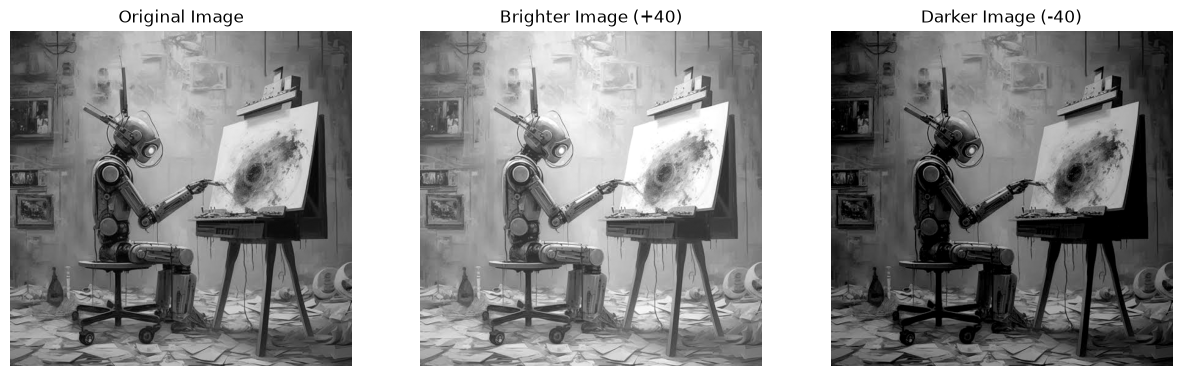

In [5]:
# Image brightness adjustment
# int16 is used to prevent overflow during addition or subtraction.
image_int = image.astype(np.int16)

bright_image = np.clip(image_int + 40, 0, 255).astype(np.uint8)
dark_image = np.clip(image_int - 40, 0, 255).astype(np.uint8)

# Brightness +40 using nested loops
loop_bright_image = np.zeros(image.shape, dtype=np.uint8)

for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        new_value = int(image[i, j]) + 40

        if new_value > 255:
            new_value = 255
        if new_value < 0:
            new_value = 0

        loop_bright_image[i, j] = new_value

print("Does the loop result match the NumPy result?",
      np.array_equal(bright_image, loop_bright_image))

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(bright_image, cmap="gray", vmin=0, vmax=255)
plt.title("Brighter Image (+40)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dark_image, cmap="gray", vmin=0, vmax=255)
plt.title("Darker Image (-40)")
plt.axis("off")
plt.show()

**Observation:** Adding 40 makes the image brighter, while subtracting 40 makes it darker. Clipping keeps all pixel values in the valid range of 0 to 255. The nested-loop result should match the NumPy result.

# Exercise 2 – Linear contrast from zero

Formula: `s = αr + β`

Here, α = 1.5 and β = 0. The pixel value is multiplied by 1.5.

### Dry run

Given pixels: `[30, 80, 128, 180, 240]`

Raw results: `[45, 120, 192, 270, 360]`  
After clipping and truncation: `[45, 120, 192, 255, 255]`

The last two pixels become saturated at 255. Their original highlight differences are lost.

In [6]:
# Dry-run verification
pixels = np.array([30, 80, 128, 180, 240], dtype=np.float64)
raw_values = 1.5 * pixels
final_values = np.clip(raw_values, 0, 255).astype(np.uint8)

print("Raw values:", raw_values)
print("Final values:", final_values)

Raw values: [ 45. 120. 192. 270. 360.]
Final values: [ 45 120 192 255 255]


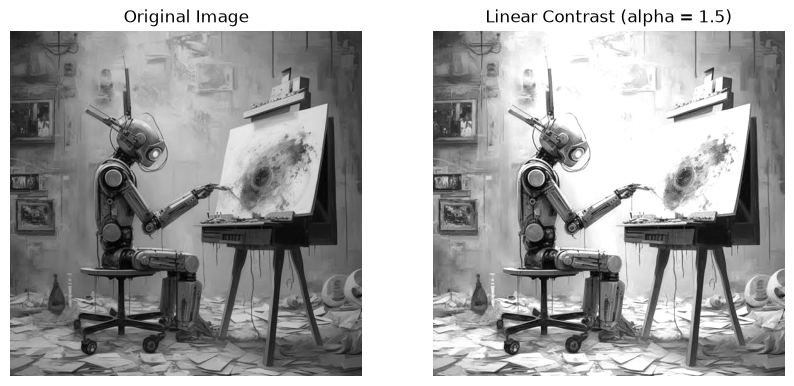

In [7]:
# Apply linear contrast from zero to the image
contrast_zero = np.clip(image.astype(np.float64) * 1.5, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_zero, cmap="gray", vmin=0, vmax=255)
plt.title("Linear Contrast (alpha = 1.5)")
plt.axis("off")
plt.show()

**Observation:** Multiplication by 1.5 increases pixel values and makes the image brighter with stronger contrast in many areas. Bright pixels may reach 255 and lose detail due to clipping.

# Exercise 3 – Contrast centered at 128

Formula: `s = (r − 128) × α + 128`

We use α = 1.5 and α = 0.5.

### Dry run

Given pixels: `[30, 80, 128, 180, 240]`

For α = 1.5:

- Intermediate values `(r − 128)`: `[-98, -48, 0, 52, 112]`
- Raw results: `[-19, 56, 128, 206, 296]`
- Final values after clipping: `[0, 56, 128, 206, 255]`

For α = 0.5:

- Intermediate values `(r − 128)`: `[-98, -48, 0, 52, 112]`
- Raw results: `[79, 104, 128, 154, 184]`
- Final values: `[79, 104, 128, 154, 184]`

At r = 128, the result remains 128 for both values of α. This is because 128 is the center point.

In [8]:
# Dry-run verification
pixels = np.array([30, 80, 128, 180, 240], dtype=np.float64)
intermediate = pixels - 128

raw_15 = intermediate * 1.5 + 128
result_15 = np.clip(raw_15, 0, 255).astype(np.uint8)

raw_05 = intermediate * 0.5 + 128
result_05 = np.clip(raw_05, 0, 255).astype(np.uint8)

print("Intermediate values:", intermediate)
print("Raw values for alpha 1.5:", raw_15)
print("Final values for alpha 1.5:", result_15)
print("Raw values for alpha 0.5:", raw_05)
print("Final values for alpha 0.5:", result_05)

Intermediate values: [-98. -48.   0.  52. 112.]
Raw values for alpha 1.5: [-19.  56. 128. 206. 296.]
Final values for alpha 1.5: [  0  56 128 206 255]
Raw values for alpha 0.5: [ 79. 104. 128. 154. 184.]
Final values for alpha 0.5: [ 79 104 128 154 184]


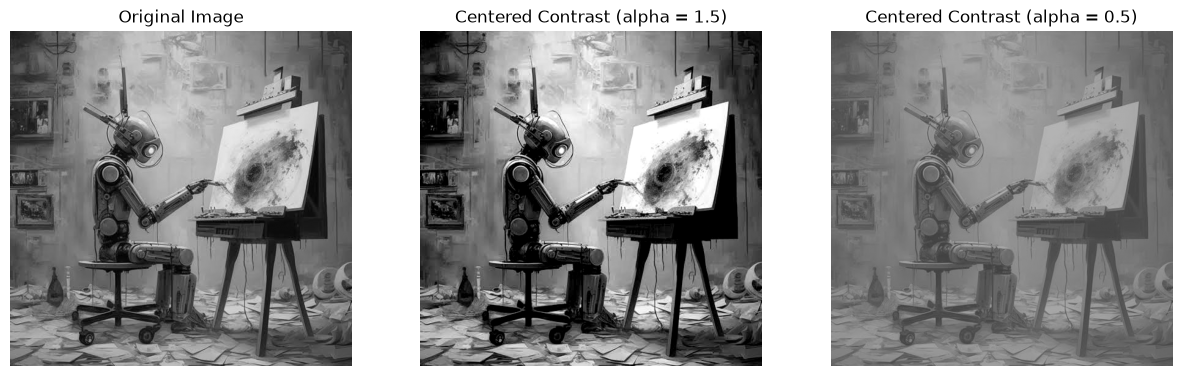

In [9]:
# Apply centered contrast to the image
image_float = image.astype(np.float64)

contrast_15 = np.clip((image_float - 128) * 1.5 + 128, 0, 255).astype(np.uint8)
contrast_05 = np.clip((image_float - 128) * 0.5 + 128, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(contrast_15, cmap="gray", vmin=0, vmax=255)
plt.title("Centered Contrast (alpha = 1.5)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(contrast_05, cmap="gray", vmin=0, vmax=255)
plt.title("Centered Contrast (alpha = 0.5)")
plt.axis("off")
plt.show()

**Observation:** α = 1.5 increases contrast around the middle intensity 128. α = 0.5 reduces contrast by moving values closer to 128. Unlike contrast from zero, the center value stays fixed at 128.

# Exercise 4 – Image negative

Formula: `s = 255 − r`

The negative transformation changes dark pixels into bright pixels and bright pixels into dark pixels.

### Dry run

Original pixels: `[30, 80, 128, 180, 240]`  
Negative: `[225, 175, 127, 75, 15]`  
Applying the negative again: `[30, 80, 128, 180, 240]`

The second negative returns the original values.

In [10]:
# Dry-run verification
pixels = np.array([30, 80, 128, 180, 240], dtype=np.uint8)
negative_pixels = 255 - pixels
negative_again = 255 - negative_pixels

print("Negative:", negative_pixels)
print("Negative applied again:", negative_again)
print("Same as original?", np.array_equal(pixels, negative_again))

Negative: [225 175 127  75  15]
Negative applied again: [ 30  80 128 180 240]
Same as original? True


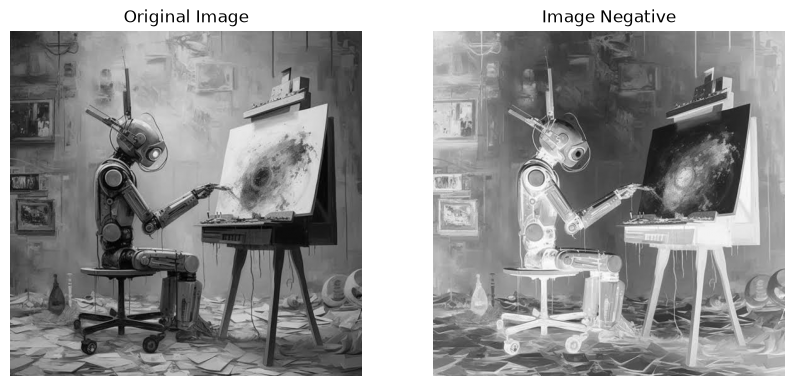

In [11]:
# Create image negative
negative_image = 255 - image

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(negative_image, cmap="gray", vmin=0, vmax=255)
plt.title("Image Negative")
plt.axis("off")
plt.show()

**Observation:** The negative image reverses the intensity values. It can help inspect details in a dark region, such as small bright structures that are difficult to see in the original image.

# Exercise 5 – Gamma correction

Formula: `s = 255 × (r / 255)^γ`

We use γ = 0.5 and γ = 2.0. First, each pixel is normalized by dividing it by 255. Then the normalized value is raised to γ and multiplied by 255.

### Dry run

Given pixels: `[0, 64, 128, 192, 255]`

For γ = 0.5, the final truncated values are approximately: `[0, 127, 180, 221, 255]`.

For γ = 2.0, the final truncated values are: `[0, 16, 64, 144, 255]`.

Both 0 and 255 stay fixed. With this formula, γ = 0.5 makes middle and dark values brighter, while γ = 2.0 makes them darker. The calculation keeps full precision until the final conversion to `uint8`.

In [12]:
# Dry-run verification with full precision
pixels = np.array([0, 64, 128, 192, 255], dtype=np.float64)
normalized = pixels / 255

gamma_05_power = normalized ** 0.5
gamma_05_scaled = 255 * gamma_05_power
gamma_05_result = gamma_05_scaled.astype(np.uint8)

gamma_20_power = normalized ** 2.0
gamma_20_scaled = 255 * gamma_20_power
gamma_20_result = gamma_20_scaled.astype(np.uint8)

print("Normalized values:", normalized)
print("Power values for gamma 0.5:", gamma_05_power)
print("Scaled values for gamma 0.5:", gamma_05_scaled)
print("Final values for gamma 0.5:", gamma_05_result)
print()
print("Power values for gamma 2.0:", gamma_20_power)
print("Scaled values for gamma 2.0:", gamma_20_scaled)
print("Final values for gamma 2.0:", gamma_20_result)

Normalized values: [0.         0.25098039 0.50196078 0.75294118 1.        ]
Power values for gamma 0.5: [0.         0.50097943 0.70849191 0.86772183 1.        ]
Scaled values for gamma 0.5: [  0.         127.74975538 180.66543665 221.26906698 255.        ]
Final values for gamma 0.5: [  0 127 180 221 255]

Power values for gamma 2.0: [0.         0.06299116 0.25196463 0.56692042 1.        ]
Scaled values for gamma 2.0: [  0.          16.0627451   64.25098039 144.56470588 255.        ]
Final values for gamma 2.0: [  0  16  64 144 255]


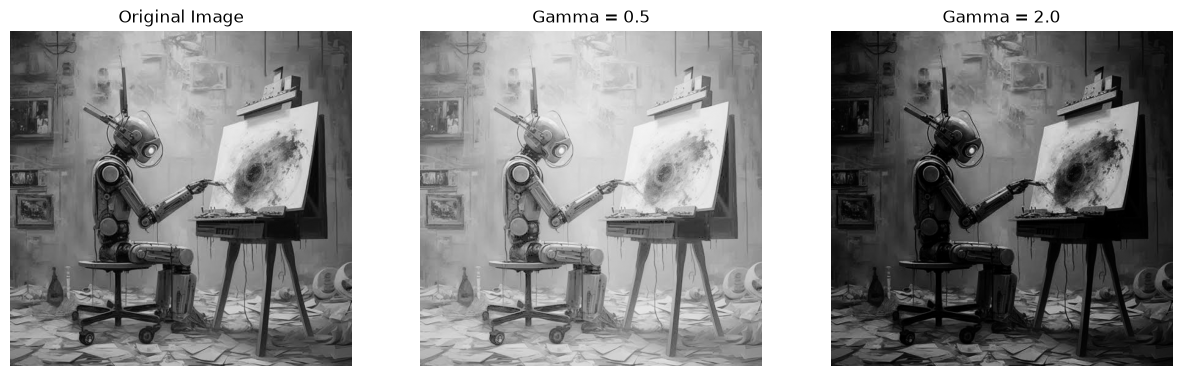

In [13]:
# Apply gamma correction to the image
image_normalized = image.astype(np.float64) / 255

gamma_image_05 = (255 * (image_normalized ** 0.5)).astype(np.uint8)
gamma_image_20 = (255 * (image_normalized ** 2.0)).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gamma_image_05, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 0.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gamma_image_20, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 2.0")
plt.axis("off")
plt.show()

**Observation:** Gamma correction changes brightness in a non-linear way. In this formula, gamma below 1 brightens dark and middle regions, while gamma above 1 darkens them. This is the gamma convention used in this lab formula.

# Exercise 6 – Grayscale histogram

A grayscale histogram counts how many pixels have each intensity value. We use 256 bins, covering intensity values from 0 to 255, with the histogram range set to 0–256.

### Dry run

Given matrix:

`A = [[0, 50, 50, 100], [100, 150, 200, 255]]`

There are 8 pixels in total.

| Intensity | Frequency | Probability |
|---:|---:|---:|
| 0 | 1 | 1/8 = 0.125 |
| 50 | 2 | 2/8 = 0.250 |
| 100 | 2 | 2/8 = 0.250 |
| 150 | 1 | 1/8 = 0.125 |
| 200 | 1 | 1/8 = 0.125 |
| 255 | 1 | 1/8 = 0.125 |
| **Total** | **8** | **1.000** |

A histogram does not show pixel positions because it only counts intensity values, not where those pixels occur in the image.

In [14]:
# Dry-run verification
A = np.array([[0, 50, 50, 100],
              [100, 150, 200, 255]], dtype=np.uint8)

values, counts = np.unique(A, return_counts=True)
probabilities = counts / A.size

print("Total number of pixels:", A.size)
print("Intensity values:", values)
print("Frequencies:", counts)
print("Probabilities:", probabilities)

Total number of pixels: 8
Intensity values: [  0  50 100 150 200 255]
Frequencies: [1 2 2 1 1 1]
Probabilities: [0.125 0.25  0.25  0.125 0.125 0.125]


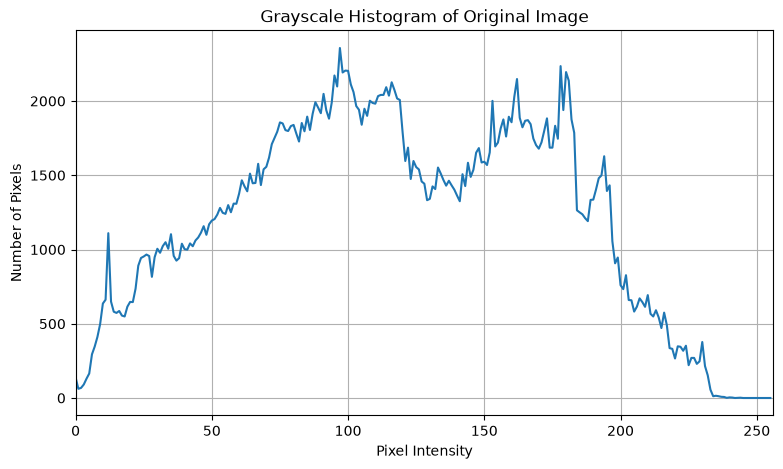

In [15]:
# Plot the original image histogram
histogram = cv2.calcHist([image], [0], None, [256], [0, 256])

plt.figure(figsize=(9, 5))
plt.plot(histogram)
plt.title("Grayscale Histogram of Original Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.xlim(0, 256)
plt.grid()
plt.show()

**Interpretation:** Look at the histogram to see whether most pixels are dark, middle gray, or bright. A histogram concentrated in a narrow range indicates that the image uses a limited range of intensity values.

# Exercise 7 – Global histogram equalization

Global histogram equalization uses the cumulative distribution of the image intensities to spread intensity values over a wider range.

We use OpenCV's `cv2.equalizeHist()` function.

### Dry run

Given pixels: `[50, 50, 100, 150]`

| Intensity | Frequency | Cumulative count | CDF |
|---:|---:|---:|---:|
| 50 | 2 | 2 | 0.50 |
| 100 | 1 | 3 | 0.75 |
| 150 | 1 | 4 | 1.00 |

Using `255 × CDF`:
- 50 → 127.5 → 128
- 100 → 191.25 → 191
- 150 → 255 → 255

First output list: `[128, 128, 191, 255]`

For the normalized formula, CDFmin = 0.50:

`255 × (CDF − CDFmin) / (1 − CDFmin)`

- 50 → 0
- 100 → 127.5 → 128
- 150 → 255

Second output list: `[0, 0, 128, 255]`

OpenCV's global equalization uses the normalized mapping for this example, so its result should be `[0, 0, 128, 255]`.

In [16]:
# Dry-run verification
pixels = np.array([50, 50, 100, 150], dtype=np.uint8)

values, counts = np.unique(pixels, return_counts=True)
cumulative_counts = np.cumsum(counts)
cdf = cumulative_counts / pixels.size
cdf_min = cdf[0]

mapping_cdf = np.round(255 * cdf).astype(int)
mapping_normalized = np.floor(
    255 * (cdf - cdf_min) / (1 - cdf_min) + 0.5
).astype(int)

print("Intensity values:", values)
print("Frequencies:", counts)
print("Cumulative counts:", cumulative_counts)
print("CDF:", cdf)
print("Output using 255 x CDF:", mapping_cdf)
print("Output using normalized CDF:", mapping_normalized)

# Make the mapped lists for all four original pixels
first_list = []
second_list = []
for value in pixels:
    position = np.where(values == value)[0][0]
    first_list.append(mapping_cdf[position])
    second_list.append(mapping_normalized[position])

print("First output list:", first_list)
print("Second output list:", second_list)

# Verify with OpenCV
small_image = pixels.reshape(1, 4)
opencv_result = cv2.equalizeHist(small_image)
print("OpenCV output list:", opencv_result.flatten())

Intensity values: [ 50 100 150]
Frequencies: [2 1 1]
Cumulative counts: [2 3 4]
CDF: [0.5  0.75 1.  ]
Output using 255 x CDF: [128 191 255]
Output using normalized CDF: [  0 128 255]
First output list: [np.int64(128), np.int64(128), np.int64(191), np.int64(255)]
Second output list: [np.int64(0), np.int64(0), np.int64(128), np.int64(255)]
OpenCV output list: [  0   0 128 255]


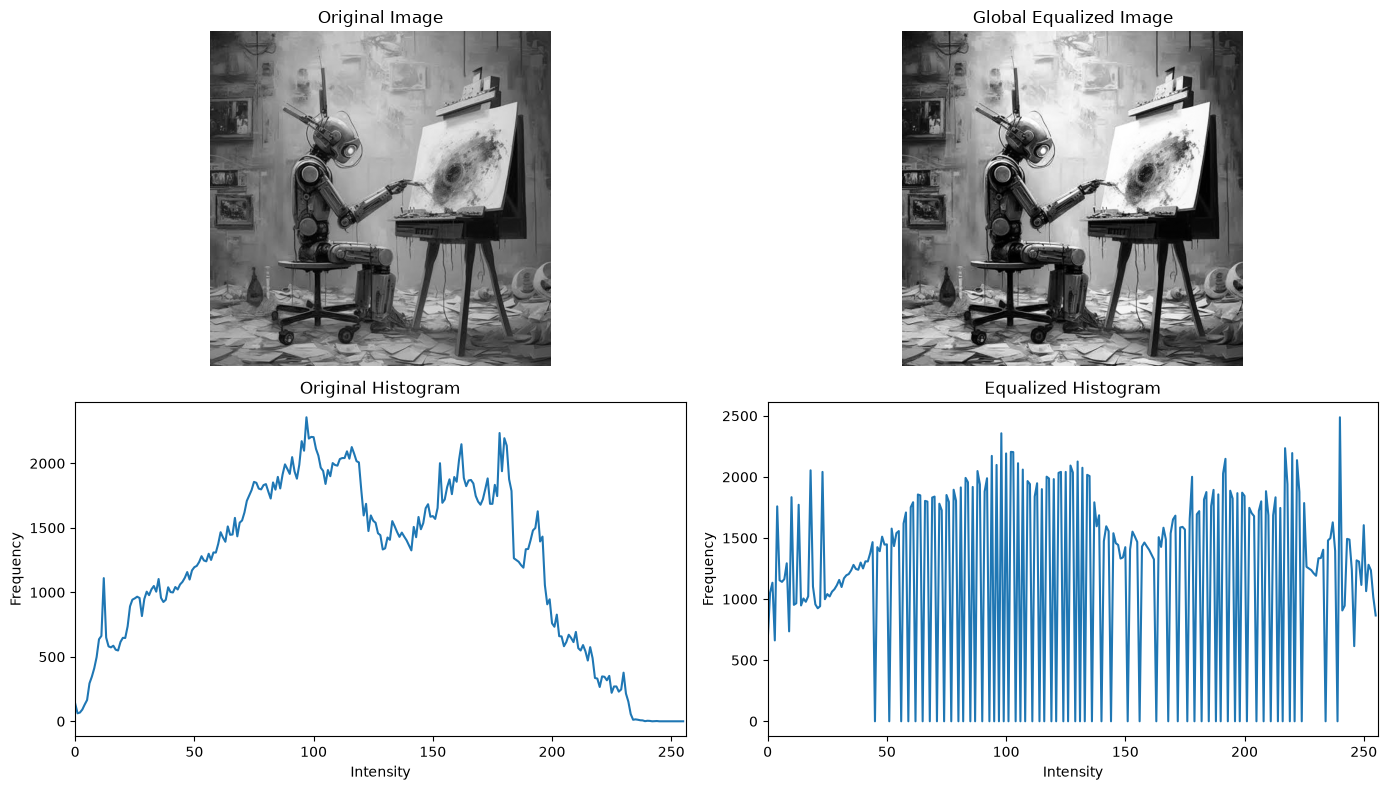

In [17]:
# Apply global histogram equalization
equalized_image = cv2.equalizeHist(image)

original_hist = cv2.calcHist([image], [0], None, [256], [0, 256])
equalized_hist = cv2.calcHist([equalized_image], [0], None, [256], [0, 256])

plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized_image, cmap="gray", vmin=0, vmax=255)
plt.title("Global Equalized Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.plot(original_hist)
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 256)

plt.subplot(2, 2, 4)
plt.plot(equalized_hist)
plt.title("Equalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 256)

plt.tight_layout()
plt.show()

**Observation:** Global equalization may improve contrast when the original image uses a narrow intensity range. It can also make noise more visible because it increases contrast in areas containing noise.

# Exercise 8 – CLAHE

CLAHE means Contrast Limited Adaptive Histogram Equalization. It improves contrast in small local areas instead of using one histogram for the whole image.

Required settings:
- `clipLimit = 2.0`
- `tileGridSize = (8, 8)`

The value `(8, 8)` means 8 tiles across and 8 tiles down. It does not mean 8 pixels per tile.

### Dry run

Given four-bin histogram: `[6, 2, 0, 0]`  
Absolute bin cap: 4

After clipping: `[4, 2, 0, 0]`

Excess count = 2. Redistribute equally across four bins: 2/4 = 0.5 per bin.

New histogram: `[4.5, 2.5, 0.5, 0.5]`  
Total count = 8  
New CDF: `[0.5625, 0.875, 0.9375, 1.0]`

Neighboring tiles need interpolation so that the output does not show sudden boundaries between tiles. This simplified example uses an absolute cap and is not the same as OpenCV's `clipLimit` parameter or its integer redistribution method.

In [18]:
# Dry-run verification
hist = np.array([6, 2, 0, 0], dtype=np.float64)
absolute_cap = 4

clipped_hist = np.minimum(hist, absolute_cap)
excess = np.sum(hist - clipped_hist)
redistributed_hist = clipped_hist + excess / len(hist)

new_cdf = np.cumsum(redistributed_hist) / np.sum(redistributed_hist)

print("Original histogram:", hist)
print("Clipped histogram:", clipped_hist)
print("Excess count:", excess)
print("Redistributed histogram:", redistributed_hist)
print("New CDF:", new_cdf)

Original histogram: [6. 2. 0. 0.]
Clipped histogram: [4. 2. 0. 0.]
Excess count: 2.0
Redistributed histogram: [4.5 2.5 0.5 0.5]
New CDF: [0.5625 0.875  0.9375 1.    ]


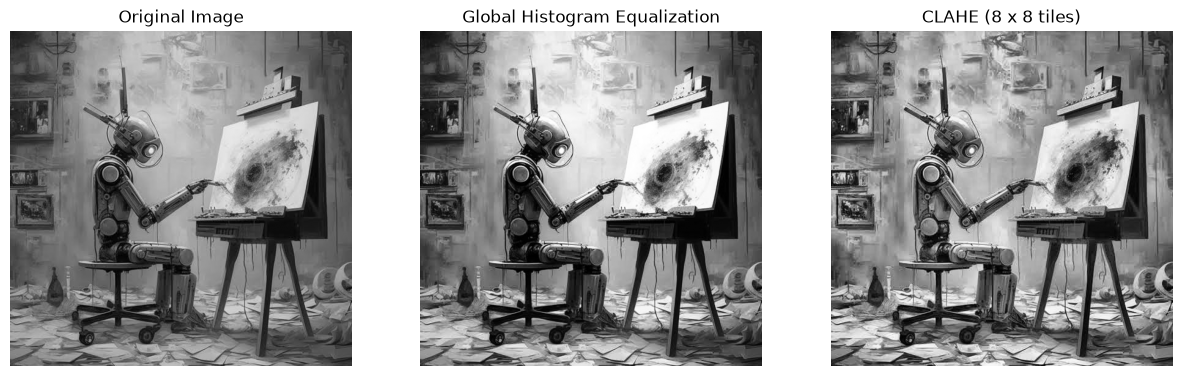

In [19]:
# Apply CLAHE to the image
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_image = clahe.apply(image)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap="gray", vmin=0, vmax=255)
plt.title("Global Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_image, cmap="gray", vmin=0, vmax=255)
plt.title("CLAHE (8 x 8 tiles)")
plt.axis("off")
plt.show()

**Observation:** Global equalization applies one mapping to the complete image. CLAHE works on local tiles and can be more useful when lighting is uneven across the image. Its contrast limit helps control excessive amplification.

# Exercise 9 – Fixed binary thresholding

Fixed thresholding changes a grayscale image into a binary image.

For this lab, the rule is:
- If `r > T`, output 255 (white).
- Otherwise, output 0 (black).

Threshold T = 127.

### Dry run

Given pixels: `[0, 80, 127, 128, 180, 255]`

For T = 127: `[0, 0, 0, 255, 255, 255]`  
Number of white pixels = 3.

For T = 180: `[0, 0, 0, 0, 0, 255]`  
Number of white pixels = 1.

In [20]:
# Dry-run verification
pixels = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)

result_127 = np.where(pixels > 127, 255, 0).astype(np.uint8)
result_180 = np.where(pixels > 180, 255, 0).astype(np.uint8)

print("Result for T = 127:", result_127)
print("White pixels for T = 127:", np.count_nonzero(result_127 == 255))
print("Result for T = 180:", result_180)
print("White pixels for T = 180:", np.count_nonzero(result_180 == 255))

Result for T = 127: [  0   0   0 255 255 255]
White pixels for T = 127: 3
Result for T = 180: [  0   0   0   0   0 255]
White pixels for T = 180: 1


Threshold used: 127.0
Unique values in binary image: [  0 255]


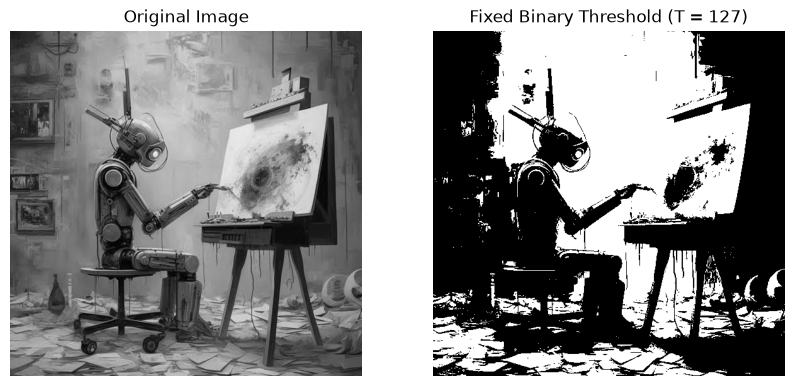

In [21]:
# Apply fixed thresholding to the image
threshold_value, binary_image = cv2.threshold(
    image, 127, 255, cv2.THRESH_BINARY
)

print("Threshold used:", threshold_value)
print("Unique values in binary image:", np.unique(binary_image))

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Binary Threshold (T = 127)")
plt.axis("off")
plt.show()

**Observation:** Fixed thresholding uses the same threshold for every pixel. It is simple and works well when foreground and background intensities are clearly separated. The output contains only 0 and 255.

# Exercise 10 – Otsu thresholding

Otsu thresholding automatically selects a threshold by finding the split that gives the largest between-class variance.

For each possible threshold:
- Class 0 contains pixels where `r ≤ T`.
- Class 1 contains pixels where `r > T`.
- Calculate class weights `w0`, `w1` and class means `μ0`, `μ1`.
- Calculate `w0 × w1 × (μ0 − μ1)²`.
- Choose the smallest threshold if multiple thresholds have the same maximum score.

### Dry run

Pixels: `[0, 1, 4, 5]`

The maximum score is 4.0. Thresholds T = 1, 2, and 3 tie, so the smallest is selected: **T = 1**.

Predicted mask: `[0, 0, 255, 255]`.

In [22]:
# Dry-run verification for Otsu thresholding
pixels = np.array([0, 1, 4, 5], dtype=np.uint8)

best_score = -1
best_threshold = None

for threshold in range(5):
    class_0 = pixels[pixels <= threshold]
    class_1 = pixels[pixels > threshold]

    if len(class_0) == 0 or len(class_1) == 0:
        score = 0
        weight_0 = len(class_0) / len(pixels)
        weight_1 = len(class_1) / len(pixels)
        mean_0 = 0
        mean_1 = 0
    else:
        weight_0 = len(class_0) / len(pixels)
        weight_1 = len(class_1) / len(pixels)
        mean_0 = np.mean(class_0)
        mean_1 = np.mean(class_1)
        score = weight_0 * weight_1 * (mean_0 - mean_1) ** 2

    print("T =", threshold,
          "w0 =", weight_0,
          "w1 =", weight_1,
          "mu0 =", mean_0,
          "mu1 =", mean_1,
          "score =", score)

    if score > best_score:
        best_score = score
        best_threshold = threshold

print("Selected smallest threshold with maximum score:", best_threshold)

predicted_mask = np.where(pixels > best_threshold, 255, 0).astype(np.uint8)
print("Predicted mask:", predicted_mask)

# Verify with OpenCV
small_image = pixels.reshape(1, 4)
otsu_value, otsu_mask = cv2.threshold(
    small_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print("OpenCV Otsu threshold:", otsu_value)
print("OpenCV Otsu mask:", otsu_mask.flatten())

T = 0 w0 = 0.25 w1 = 0.75 mu0 = 0.0 mu1 = 3.3333333333333335 score = 2.0833333333333335
T = 1 w0 = 0.5 w1 = 0.5 mu0 = 0.5 mu1 = 4.5 score = 4.0
T = 2 w0 = 0.5 w1 = 0.5 mu0 = 0.5 mu1 = 4.5 score = 4.0
T = 3 w0 = 0.5 w1 = 0.5 mu0 = 0.5 mu1 = 4.5 score = 4.0
T = 4 w0 = 0.75 w1 = 0.25 mu0 = 1.6666666666666667 mu1 = 5.0 score = 2.083333333333333
Selected smallest threshold with maximum score: 1
Predicted mask: [  0   0 255 255]
OpenCV Otsu threshold: 1.0
OpenCV Otsu mask: [  0   0 255 255]


Otsu threshold returned by OpenCV: 119.0
Unique values in Otsu image: [  0 255]


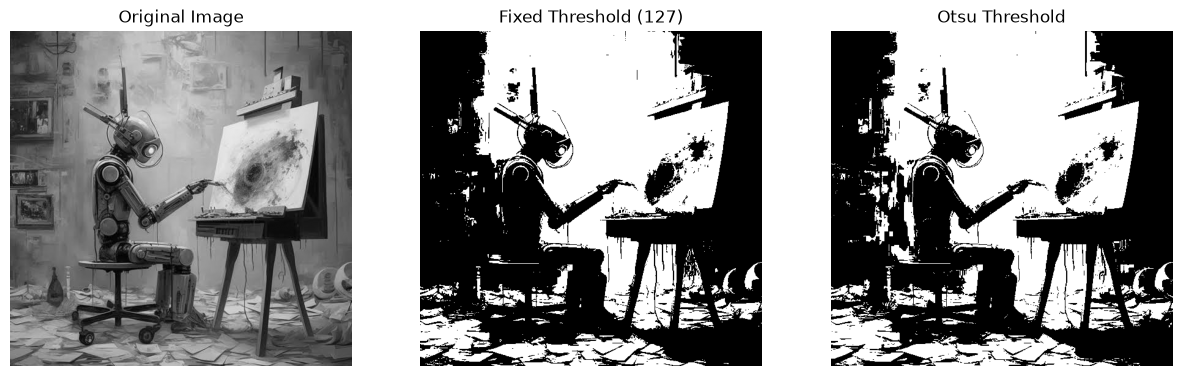

In [23]:
# Apply Otsu thresholding to the image
otsu_value, otsu_image = cv2.threshold(
    image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu threshold returned by OpenCV:", otsu_value)
print("Unique values in Otsu image:", np.unique(otsu_image))

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold (127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_image, cmap="gray", vmin=0, vmax=255)
plt.title("Otsu Threshold")
plt.axis("off")
plt.show()

**Observation:** Otsu chooses a threshold automatically based on the image histogram. It is useful when the image has two main intensity groups. Its mask can differ from the fixed-threshold mask because the threshold is selected from the image data.

# Exercise 11 – Adaptive Gaussian thresholding

Adaptive thresholding calculates a different threshold for each local neighborhood. This can help when an image has uneven lighting.

Required settings:
- Gaussian weighting
- Binary output
- `blockSize = 11`
- `C = 2`

### Dry run

Neighborhood:

`[[100, 100, 100], [100, 120, 140], [140, 140, 140]]`

Gaussian weights:

`[[1, 2, 1], [2, 4, 2], [1, 2, 1]] / 16`

Weighted mean = 120  
Local threshold = mean − C = 120 − 2 = 118

The center pixel is 120. Since 120 > 118, it becomes 255 (white).

A pixel equal to the threshold is classified as 0 because the rule is `r > T`.

In [24]:
# Dry-run verification
neighborhood = np.array([
    [100, 100, 100],
    [100, 120, 140],
    [140, 140, 140]
], dtype=np.float64)

weights = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float64) / 16

weighted_mean = np.sum(neighborhood * weights)
local_threshold = weighted_mean - 2

center_pixel = neighborhood[1, 1]
center_result = 255 if center_pixel > local_threshold else 0
equal_pixel_result = 255 if local_threshold > local_threshold else 0

print("Weighted mean:", weighted_mean)
print("Local threshold:", local_threshold)
print("Center pixel:", center_pixel)
print("Center pixel output:", center_result)
print("Pixel equal to threshold output:", equal_pixel_result)

Weighted mean: 120.0
Local threshold: 118.0
Center pixel: 120.0
Center pixel output: 255
Pixel equal to threshold output: 0


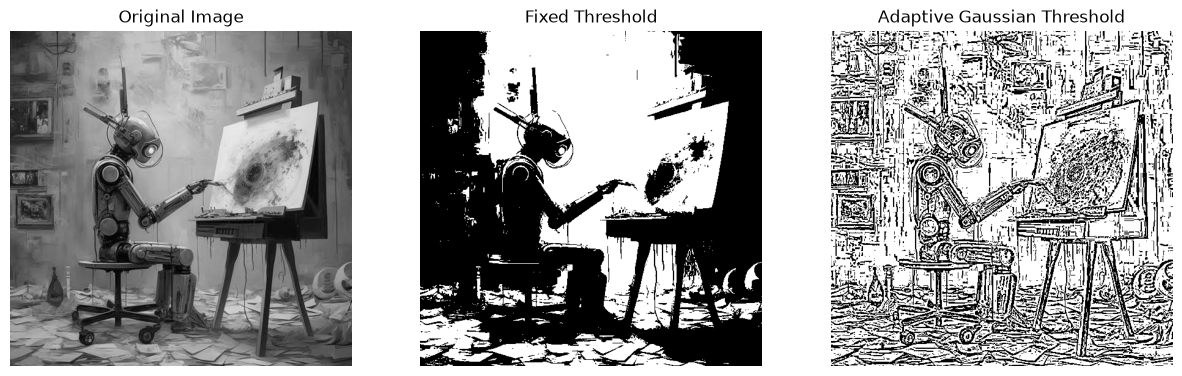

In [25]:
# Apply adaptive Gaussian thresholding to the image
adaptive_image = cv2.adaptiveThreshold(
    image,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(adaptive_image, cmap="gray", vmin=0, vmax=255)
plt.title("Adaptive Gaussian Threshold")
plt.axis("off")
plt.show()

**Observation:** Fixed and Otsu thresholding use one threshold for the whole image. Adaptive thresholding uses local neighborhood information, so it can work better when some parts of the image are brighter or darker than others.